# Household power (big regression dataset)

UCI Individual household electric power consumption: one house, one row per minute,
Dec 2006 - Nov 2010 (~2M rows). Target `Global_active_power` (kW), metric MSE. Steps 1-3.

Source: <https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption>

In [1]:
import sys
sys.path.append("..")

import pandas as pd
from IPython.display import display

from lab import FIGURES_DIR, RESULTS_DIR
from lab.experiment import baseline_score, cross_validate_models, run_learning_curve, summarize
from lab.models import make_model
from lab.plotting import plot_learning_curve
from lab.sampler import linear_sizes, log_sizes, sample_training_sets

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4g}".format)

In [2]:
DATASET = "power"
TASK = "regression"
KINDS = ["linear", "quadratic"]
N_REPEATS = 5

# None = all ~2M minutes; e.g. 100_000 for a quick test
MAX_ROWS = None
CV_MAX_ROWS = 500_000   # CV on a random subset (speed)

## Data
Features: reactive power, voltage, the three sub-meterings, and hour, weekday and month
(categorical). Minutes without measurements (~1.25%) are dropped. `Global_intensity` is dropped
because power ≈ voltage × current, i.e. it leaks the target.

In [3]:
from lab.data_power import load_power

X, y, time = load_power(max_rows=MAX_ROWS)
print(f"{len(X):,} minutes from {time.min():%Y-%m-%d} to {time.max():%Y-%m-%d}")
display(X.head())
display(y.describe())

2,049,280 minutes from 2006-12-16 to 2010-11-26


,Global_reactive_power,Voltage,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,weekday,month
0,0.418,234.8,0,1,17,17,5,12
1,0.436,233.6,0,1,16,17,5,12
2,0.498,233.3,0,2,17,17,5,12
3,0.502,233.7,0,1,17,17,5,12
4,0.528,235.7,0,1,17,17,5,12


count   2.049e+06
mean        1.092
std         1.057
min         0.076
25%         0.308
50%         0.602
75%         1.528
max         11.12
Name: Global_active_power, dtype: float64

## Train / validation split
Neighbouring minutes are almost identical, so a minute-level random split would put
near-copies of every validation minute into training. We use a random 20% of whole calendar
weeks as validation (random weeks rather than the last 20% in time, which would be only summer
and autumn 2010). CV uses `GroupKFold` with the same weeks.

The learning-curve samples are drawn at random from the training part.

In [4]:
from lab.data_power import split_power, week_groups

X_train, X_val, y_train, y_val = split_power(X, y, time)
weeks = week_groups(time)
print(f"training part: {len(X_train):,} rows ({weeks.loc[X_train.index].nunique()} weeks), "
      f"validation: {len(X_val):,} rows ({weeks.loc[X_val.index].nunique()} weeks)")
print("weeks on both sides:", len(set(weeks.loc[X_train.index]) & set(weeks.loc[X_val.index])))
display(pd.DataFrame({"train": y_train.describe(), "validation": y_val.describe()}))

training part: 1,631,330 rows (165 weeks), validation: 417,950 rows (42 weeks)
weeks on both sides: 0


,train,validation
count,1.631e+06,4.18e+05
mean,1.087,1.109
std,1.062,1.038
min,0.076,0.1
25%,0.304,0.324
50%,0.586,0.676
75%,1.526,1.534
max,11.12,10.29


In [5]:
# number of features after one-hot / squaring
for kind in KINDS:
    prep = make_model(kind).named_steps["prep"].fit(X_train)
    print(f"{kind:>20}: {prep.transform(X_train.iloc[:5]).shape[1]} features")

              linear: 48 features


           quadratic: 63 features


## Steps 1 and 2: learning curves

In [6]:
# log-spaced sizes up to the whole training part
sizes = log_sizes(10, len(X_train), 16)
print(sizes)

samples = sample_training_sets(y_train, sizes, N_REPEATS, TASK)
curve = run_learning_curve(X_train, y_train, X_val, y_val, KINDS, samples, TASK)
curve.to_csv(RESULTS_DIR / f"{DATASET}_curve.csv", index=False)

stats = summarize(curve)
display(stats)
print(f"total fitting time: {curve['fit_seconds'].sum():.0f} s")

[10, 22, 50, 110, 245, 546, 1216, 2707, 6026, 13413, 29856, 66455, 147922, 329258, 732890, 1631330]
size       10


size       22


size       50


size      110


size      245


...

size   329258


size   732890


size  1631330


model     size train_score                                          \
                              mean       std    median       q25       q75   
0      linear       10   9.264e-31 5.562e-31 8.838e-31 5.029e-31 1.404e-30   
1      linear       22   1.508e-30 6.316e-31 1.425e-30 1.182e-30 1.953e-30   
2      linear       50     0.02089   0.01861   0.01901  0.006921   0.02616   
3      linear      110       0.132    0.0283    0.1386    0.1222    0.1426   
4      linear      245      0.1473   0.03099    0.1402    0.1277    0.1778   
5      linear      546      0.1555   0.01964    0.1478    0.1417    0.1692   
6      linear     1216      0.2057   0.02282     0.217    0.1939    0.2213   
7      linear     2707      0.1886   0.01483    0.1924     0.187    0.1952   
8      linear     6026       0.202   0.01154    0.2002    0.1958    0.2074   
9      linear    13413      0.1991  0.003314    0.1977    0.1974    0.1988   
10     linear    29856      0.2033  0.002167    0.2037    0.2018     0.204   
11     linear    66455      0.2014   0.00454     0.203    0.1971    0.2032   
12     linear   147922      0.2031  0.001632     0.203    0.2021     0.204   
13     linear   329258      0.2018 0.0008596    0.2018    0.2014    0.2023   
14     linear   732890      0.2021 0.0008567    0.2024    0.2015    0.2025   
15     linear  1631330      0.2021         0    0.2021    0.2021    0.2021   
16  quadratic       10   7.836e-31 8.011e-31 3.902e-31 2.806e-31 1.026e-30   
17  quadratic       22   2.027e-30 7.756e-31 1.925e-30  1.73e-30 2.506e-30   
18  quadratic       50   8.346e-29 1.067e-28 1.593e-29 1.386e-29 1.344e-28   
19  quadratic      110       0.093   0.03196   0.08878   0.06414    0.1108   
20  quadratic      245      0.1285   0.03051    0.1219     0.104    0.1491   
21  quadratic      546      0.1462   0.02065    0.1431    0.1292    0.1589   
22  quadratic     1216      0.2008   0.02187    0.2107    0.1905    0.2163   
23  quadratic     2707       0.185   0.01464    0.1882    0.1832    0.1924   
24  quadratic     6026      0.1997   0.01102    0.1982    0.1941    0.2051   
25  quadratic    13413      0.1966  0.003084    0.1954    0.1951    0.1961   
26  quadratic    29856       0.201  0.002153    0.2016    0.1992    0.2016   
27  quadratic    66455      0.1995  0.004639    0.2009    0.1952    0.2016   
28  quadratic   147922       0.201  0.001708    0.2011    0.1998    0.2019   
29  quadratic   329258      0.1997 0.0008373    0.1997    0.1993    0.2003   
30  quadratic   732890         0.2 0.0008484    0.2004    0.1995    0.2004   
31  quadratic  1631330         0.2         0       0.2       0.2       0.2   

   val_score                                 
        mean       std median    q25    q75  
0       10.6     8.931  6.322  6.011  19.47  
1      1.564     1.008  1.174  0.908  1.663  
2      67.31     105.2 0.7927 0.5461  93.64  
3     0.3247   0.06015 0.3034 0.2992 0.3697  
4     0.2276   0.03769 0.2105 0.2044 0.2318  
5     0.1974   0.01355  0.195 0.1892 0.1981  
6     0.1838   0.00316 0.1819 0.1818 0.1849  
7     0.1793  0.001279 0.1794 0.1788 0.1805  
8     0.1773  0.001555 0.1769 0.1765 0.1775  
9     0.1763 0.0003968 0.1762 0.1762 0.1766  
10    0.1759 0.0003869 0.1758 0.1756 0.1761  
11    0.1757 0.0004476 0.1759 0.1756  0.176  
12    0.1757 9.441e-05 0.1756 0.1756 0.1757  
13    0.1755 8.136e-05 0.1755 0.1755 0.1755  
14    0.1755 4.481e-05 0.1755 0.1755 0.1755  
15    0.1755         0 0.1755 0.1755 0.1755  
16      2418      2948  650.9  193.9   5218  
17     266.4     268.4  275.7   9.98  421.9  
18      1963      4203  38.77  2.957    293  
19     159.9     181.1  102.1  28.09  222.8  
20     1.996     2.405 0.6434 0.4608  2.748  
21    0.2638   0.07098 0.2307 0.2203 0.2742  
22    0.1885  0.006119 0.1885 0.1846 0.1886  
23    0.1808  0.002808 0.1803 0.1792 0.1824  
24    0.1762  0.001526 0.1759 0.1756 0.1766  
25     0.175 0.0003236 0.1751  0.175 0.1751  
26    0.1746 0.0003978 0.1745 0.1744  0.175  
27    0.1743 0.000497

total fitting time: 53 s


baseline validation MSE: 1.0780 kW^2


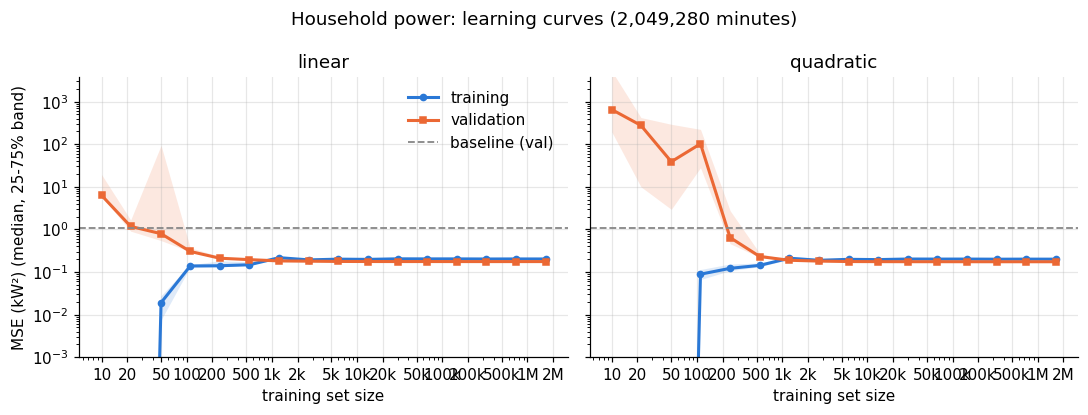

In [7]:
# baseline: predict the training mean
baseline = baseline_score(X_train, y_train, X_val, y_val, TASK)
print(f"baseline validation MSE: {baseline:.4f} kW^2")

fig = plot_learning_curve(curve, "MSE (kW²)", f"Household power: learning curves ({len(X):,} minutes)",
                          baseline=baseline, log_x=True, log_y=True, ylim=(1e-3, None),
                          path=FIGURES_DIR / f"{DATASET}_learning_curves.png")

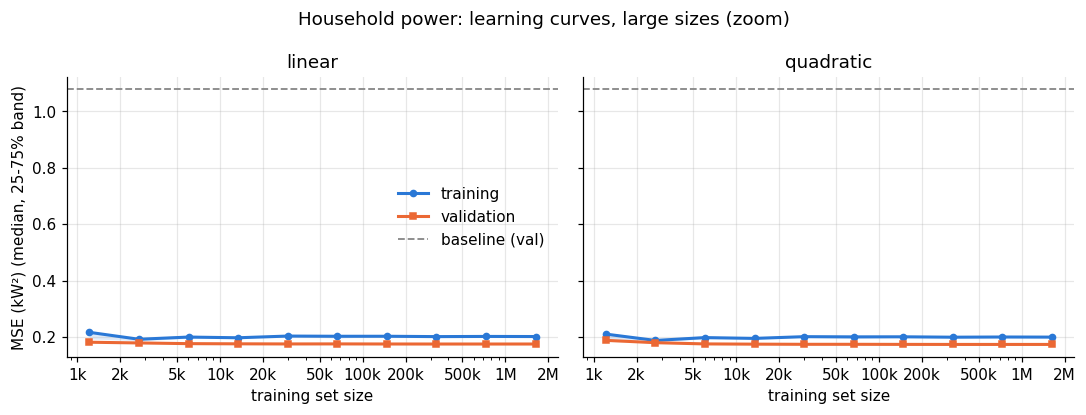

In [8]:
# zoom on the large sizes
large = curve[curve["size"] >= 1000]
fig = plot_learning_curve(large, "MSE (kW²)", "Household power: learning curves, large sizes (zoom)",
                          baseline=baseline, log_x=True,
                          path=FIGURES_DIR / f"{DATASET}_learning_curves_zoom.png")

### Explanation

**Small samples.** 48 features (linear) and 63 (quadratic) after one-hot encoding. With fewer
minutes than features the training MSE is ~0 and the validation MSE is far above the baseline
(1.08 kW²). The validation error peaks around n ≈ p (linear: n = 50, quadratic: n = 10-110),
as for the automobile data, with very wide bands.

**Large samples.** From a few thousand minutes on the curves are flat at ~0.20 (training) and
~0.175 kW² (validation). More data does not help, so the remaining error is bias plus noise.
That is still ~84% of the variance explained, mostly by the sub-meterings; the rest is the
unmetered part of the house.

**Validation below training.** The models cannot overfit here (~50 coefficients, 1.6M rows),
so this only means that the 42 validation weeks are a bit easier than average. The CV error
below (~0.205) matches the training error.

**Quadratic.** Needs more data before it is usable, then ends slightly lower (0.1741 vs
0.1755).

## Random minutes vs whole weeks
Both models fitted on the full training part, with our week split and with a minute-level
random split (`split_power_random`).

In [9]:
from lab.data_power import split_power_random
from lab.experiment import score

rows = []
for name, parts in [("whole weeks", split_power(X, y, time)), ("random minutes", split_power_random(X, y))]:
    Xa, Xb, ya, yb = parts
    for kind in KINDS:
        model = make_model(kind).fit(Xa, ya)
        rows.append({"split": name, "model": kind,
                     "train_mse": score(model, Xa, ya, TASK), "val_mse": score(model, Xb, yb, TASK)})
display(pd.DataFrame(rows))

,split,model,train_mse,val_mse
0,whole weeks,linear,0.2021,0.1755
1,whole weeks,quadratic,0.2,0.1741
2,random minutes,linear,0.1968,0.1947
3,random minutes,quadratic,0.1949,0.1927


The random split does not look better here (its validation MSE is even slightly higher). A
linear model with ~50 coefficients on 1.6M rows cannot memorize single minutes, so the leakage
does not help it; a model like k-NN would profit. We keep the week split because it measures
performance on unseen days for any model.

## Step 3: cross-validation
5-fold `GroupKFold` by week on a random 500k-row subset of the training part.

In [10]:
from sklearn.model_selection import GroupKFold

cv = cross_validate_models(X_train, y_train, KINDS, TASK, folds=GroupKFold(n_splits=5),
                           groups=weeks.loc[X_train.index], max_rows=CV_MAX_ROWS)
cv.to_csv(RESULTS_DIR / f"{DATASET}_cv.csv", index=False)

largest = stats[stats["size"] == stats["size"].max()]
curve_end = pd.DataFrame({
    "model": largest["model"],
    "curve_train": largest[("train_score", "median")],
    "curve_val": largest[("val_score", "median")],
})
comparison = cv.merge(curve_end, on="model")
display(comparison)
print("CV chooses:", cv.loc[cv["cv_mean"].idxmin(), "model"])

,model,cv_mean,cv_std,n_rows,curve_train,curve_val
0,linear,0.2058,0.02434,500000,0.2021,0.1755
1,quadratic,0.2044,0.02437,500000,0.2,0.1741


CV chooses: quadratic


### CV vs. learning curves

CV slightly prefers the **quadratic** model, same as the validation curves.

- CV, training and validation errors are all close: with this much data the models cannot
  overfit.
- The difference between the models (~0.0015 kW²) is much smaller than `cv_std` (~0.024), but
  quadratic is better in 4 of the 5 folds (the same folds for both models). In practice they
  are about equally good.
- The CV error (~0.205) is above the validation error (~0.175) because the validation weeks
  happen to be easier.